# Model run

In [1]:
# Set scenario name
SCENARIO_NAME = 'test'
NEW_MT_CENTRES = ['RG15AN']

In [2]:
import contextily as ctx
import geopandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classes.geography_processing import Geoprocessing
from classes.model import Model
from classes.scenario import Scenario
from classes.add_net_benefit import add_net_benefit


In [3]:
# Allow for a travel bias time (minutes) to MT centres
MT_travel_bias = 1

# Process and save geographic data (only needed when hospital data changes)
geo = Geoprocessing(mt_travel_bias = MT_travel_bias, new_mt_centres = NEW_MT_CENTRES)
geo.run()

# Set up scenario
scenario = Scenario({
    'name': SCENARIO_NAME,
    'limit_to_england' : True
})

# Set up model
model = Model(
    scenario=scenario,
    geodata=pd.read_csv('processed_data/processed_data.csv'))

# Run model
model.run()


The input mRS distributions might be improperly labelled.
The input mRS distributions might be improperly labelled.


In [ ]:
results = model.full_results
# Add net benefit column
results = add_net_benefit(results, prop_lvo=0.3)
# Save results to CSV
results.to_csv(f'./output/results_full_{SCENARIO_NAME}.csv')

In [6]:
results.head()

,nearest_ivt_unit,nearest_ivt_time,nearest_ivt_unit_no_bias,nearest_ivt_time_no_bias,nearest_mt_unit,nearest_mt_time,transfer_unit,transfer_required,transfer_time,area_lower,...,lvo_mothership_ivt_mt_utility_shift,drip_ship_utility_shift,mothership_utility_shift,nlvo_drip_ship_ivt_improvement_over_no_treatment,lvo_drip_ship_ivt_improvement_over_no_treatment,no_treatment_mrs_0-2,drip_ship_mrs_0-2,drip_ship_mrs_0-2_improvement_over_no_treatment,mothership_mrs_0-2,mothership_mrs_0-2_improvement_over_no_treatment
LSOA,,,,,,,,,,,,,,,,,,,,,
ADUR001A,BN25BE,10,BN25BE,11,BN25BE,11,BN25BE,False,0,Adur 001A,...,0.155584,0.114428,0.124652,0.120947,0.060172,0.4855,0.608202,0.122702,0.619167,0.133667
ADUR001B,BN25BE,11,BN25BE,12,BN25BE,12,BN25BE,False,0,Adur 001B,...,0.154986,0.113964,0.124185,0.120497,0.059881,0.4855,0.607699,0.122199,0.618658,0.133158
ADUR001C,BN112DH,11,BN112DH,11,BN25BE,13,BN25BE,True,24,Adur 001C,...,0.154388,0.109743,0.123719,0.120497,0.059881,0.4855,0.603213,0.117713,0.618149,0.132649
ADUR001D,BN25BE,11,BN25BE,12,BN25BE,12,BN25BE,False,0,Adur 001D,...,0.154986,0.113964,0.124185,0.120497,0.059881,0.4855,0.607699,0.122199,0.618658,0.133158
ADUR001E,BN112DH,10,BN112DH,10,BN25BE,13,BN25BE,True,24,Adur 001E,...,0.154388,0.110205,0.123719,0.120947,0.060172,0.4855,0.603713,0.118213,0.618149,0.132649


In [7]:
# Get descriptive stats for all numeric columns
descriptive_stats = results.describe(percentiles=[0.25, 0.5, 0.75]).T
descriptive_stats.to_csv(f'./output/results_stats_{SCENARIO_NAME}.csv')
descriptive_stats

,count,mean,std,min,25%,50%,75%,max
nearest_ivt_time,32843.0,12.760010,7.972130e+00,-1.000000,7.000000,11.000000,17.000000,67.000000
nearest_ivt_time_no_bias,32843.0,13.123466,7.928949e+00,0.000000,7.000000,12.000000,17.000000,68.000000
nearest_mt_time,32843.0,24.432177,1.593591e+01,0.000000,13.000000,21.000000,32.000000,121.000000
transfer_time,32843.0,18.492281,1.812200e+01,0.000000,0.000000,20.000000,30.000000,104.000000
Admissions,32843.0,2.466063,1.418715e+00,0.100000,1.333333,2.333333,3.333333,19.333333
England,32843.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000
Admissions_2025_Est,32843.0,2.763329,1.589728e+00,0.112050,1.494030,2.614580,3.735130,21.663830
drip_ship_ivt_time,32843.0,122.760010,7.972130e+00,109.000000,117.000000,121.000000,127.000000,177.000000
drip_ship_mt_time,32843.0,261.252291,2.126066e+01,229.000000,243.000000,259.000000,273.000000,362.000000
nlvo_no_treatment_mrs_0-2,32843.0,0.580000,0.000000e+00,0.580000,0.580000,0.580000,0.580000,0.580000


In [8]:
# Repeat descriptive stats, grouped by nearest_ivt_unit
results_stats_by_unit = results.groupby('nearest_ivt_unit').describe().T
# Unpack index column so two-level index becomes two columns
results_stats_by_unit = results_stats_by_unit.reset_index()
rename_dict = {'level_0': 'variable', 'level_1': 'statistic'}
results_stats_by_unit = results_stats_by_unit.rename(columns=rename_dict)
# Save
results_stats_by_unit.to_csv(f'./output/results_stats_by_unit_{SCENARIO_NAME}.csv')
results_stats_by_unit.head()

nearest_ivt_unit,variable,statistic,B152TH,B662QT,BA13NG,BB23HH,BD96RJ,BH77DW,BL97TD,BN112DH,...,TF16TF,TQ27AA,TR13LQ,TS198PE,TS43BW,WD180HB,WF14DG,WR51DD,WV100QP,YO318HE
0,nearest_ivt_time,count,356.000000,710.000000,296.000000,301.000000,386.000000,343.000000,506.000000,181.000000,...,236.000000,173.000000,250.000000,264.000000,250.000000,467.000000,340.000000,235.000000,440.000000,309.000000
1,nearest_ivt_time,mean,11.949438,12.153521,18.388514,12.720930,10.256477,11.784257,11.565217,9.955801,...,14.733051,11.156069,22.560000,17.037879,12.228000,14.456103,12.129412,13.825532,11.952273,21.265372
2,nearest_ivt_time,std,6.202473,6.262957,9.126664,6.048294,6.932627,5.492695,4.074151,6.932070,...,8.321258,7.447017,9.851426,10.564958,9.770459,6.333684,4.862203,6.803671,6.276470,15.390189
3,nearest_ivt_time,min,1.000000,1.000000,1.000000,2.000000,0.000000,1.000000,0.000000,1.000000,...,2.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000
4,nearest_ivt_time,25%,7.000000,7.000000,12.000000,8.000000,6.000000,7.000000,9.000000,5.000000,...,8.000000,6.000000,16.000000,9.000000,5.000000,9.000000,8.000000,8.000000,7.000000,7.000000


## Map

In [9]:
# Load the England and Wales LSOA shapefile
filename = "./data/Lower_layer_super_output_areas_(E+W)_2011_Boundaries_(Generalised_Clipped)_V2.zip"
lsoa_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if lsoa_gdf.crs is None:
    lsoa_gdf = lsoa_gdf.set_crs("EPSG:27700")
else:
    lsoa_gdf = lsoa_gdf.to_crs("EPSG:27700")

# Get the England and Wales outline
filename = "zip://./data/Countries_(December_2022)_GB_BFC.zip"
countries_gdf = geopandas.read_file(filename)
if countries_gdf.crs is None:
    countries_gdf = countries_gdf.set_crs("EPSG:27700")
else:
    countries_gdf = countries_gdf.to_crs("EPSG:27700")

mask = countries_gdf["CTRY22NM"].isin(["England", "Wales"])
countries_gdf = countries_gdf.loc[mask]
england = countries_gdf.boundary

# Load hospital coordinates from CSV and create a GeoDataFrame
hospitals_df = pd.read_csv("./data/stroke_hospitals_2025.csv")
hospitals_gdf = geopandas.GeoDataFrame(
    hospitals_df,
    geometry=geopandas.points_from_xy(
        pd.to_numeric(hospitals_df["long"]),
        pd.to_numeric(hospitals_df["lat"]),
    ),
    crs="EPSG:4326",
).to_crs("EPSG:27700")

hospitals_gdf = hospitals_gdf.loc[hospitals_gdf["Country"] == "England"]
hospitals_gdf.head()

# Change 'Use_MT' values for new MT centres to hospitals_gdf
if len(NEW_MT_CENTRES) > 0:
    for new_mt_centre in NEW_MT_CENTRES:
        hospitals_gdf.loc[hospitals_gdf['Postcode'] == new_mt_centre, 'Use_MT'] = 1

In [10]:
# Merge the results with the LSOA shapefile
data = lsoa_gdf.merge(results, left_on='LSOA11NM', right_on='area_lower', how='right')

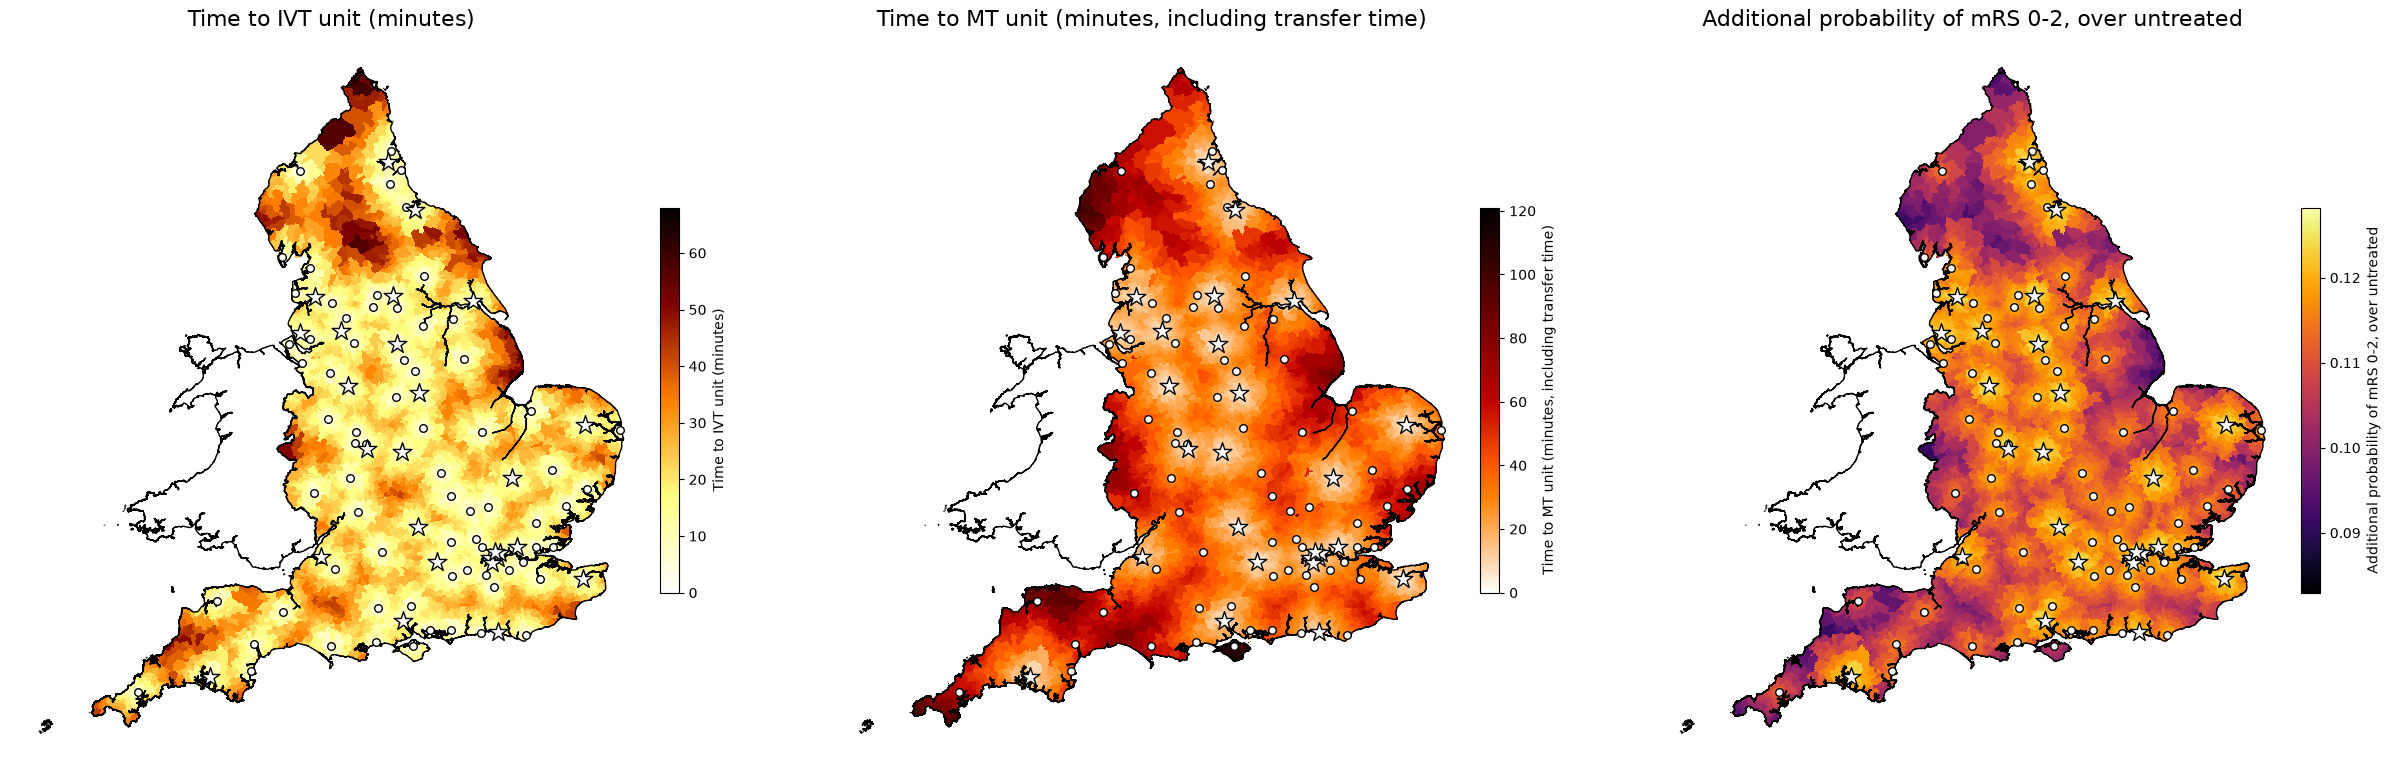

In [11]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

data['treated_improved_p_mrs_0-2'] = \
    data['drip_ship_mrs_0-2_improvement_over_no_treatment']

columns = ['nearest_ivt_time_no_bias',
           'nearest_mt_time',
           'treated_improved_p_mrs_0-2']

color_schemes = ['afmhot_r',
                 'gist_heat_r',
                 'inferno']

labels = ['Time to IVT unit (minutes)',
          'Time to MT unit (minutes, including transfer time)',
          'Additional probability of mRS 0-2, over untreated']

fig = plt.figure(figsize=(30, 10))

for i in range(3):
    ax = fig.add_subplot(1, 3, i + 1)

    column = columns[i]
    values = pd.to_numeric(data[column], errors='coerce').astype(float)
    valid_values = values.where(np.isfinite(values))

    vmin, vmax = valid_values.min(), valid_values.max()
    if vmin == vmax:
        vmax = vmin + 1

    cmap = plt.get_cmap(color_schemes[i])
    norm = Normalize(vmin=vmin, vmax=vmax)

    # Use a temporary numeric column; GeoPandas handles the color mapping.
    data['_plot_value'] = values

    data.plot(
        column='_plot_value',
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        missing_kwds={'color': 'lightgrey'},
        antialiased=False,
        linewidth=0,
    )

    england.plot(ax=ax, edgecolor='k', facecolor='none', linewidth=1)

    ivt_mask = pd.to_numeric(hospitals_gdf['Use_IVT'], errors='coerce').eq(1)
    mt_mask = pd.to_numeric(hospitals_gdf['Use_MT'], errors='coerce').eq(1)

    hospitals_gdf.loc[ivt_mask].plot(
        ax=ax, edgecolor='k', facecolor='w', markersize=30, marker='o', zorder=99
    )
    hospitals_gdf.loc[mt_mask].plot(
        ax=ax, edgecolor='k', facecolor='w', markersize=200, marker='*', zorder=99
)

    fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        shrink=0.5,      # shrink the colorbar to 50% of its original size
        pad=0.01,        # gap between map and colorbar (default 0.05)
        fraction=0.05,   # width of colorbar relative to the axes
        label=labels[i],
    )

    ax.set_title(labels[i], fontsize=16)

    ax.apply_aspect()
    ax.set_axis_off()
    
plt.savefig(f'./output/map_three_in_one_{SCENARIO_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()

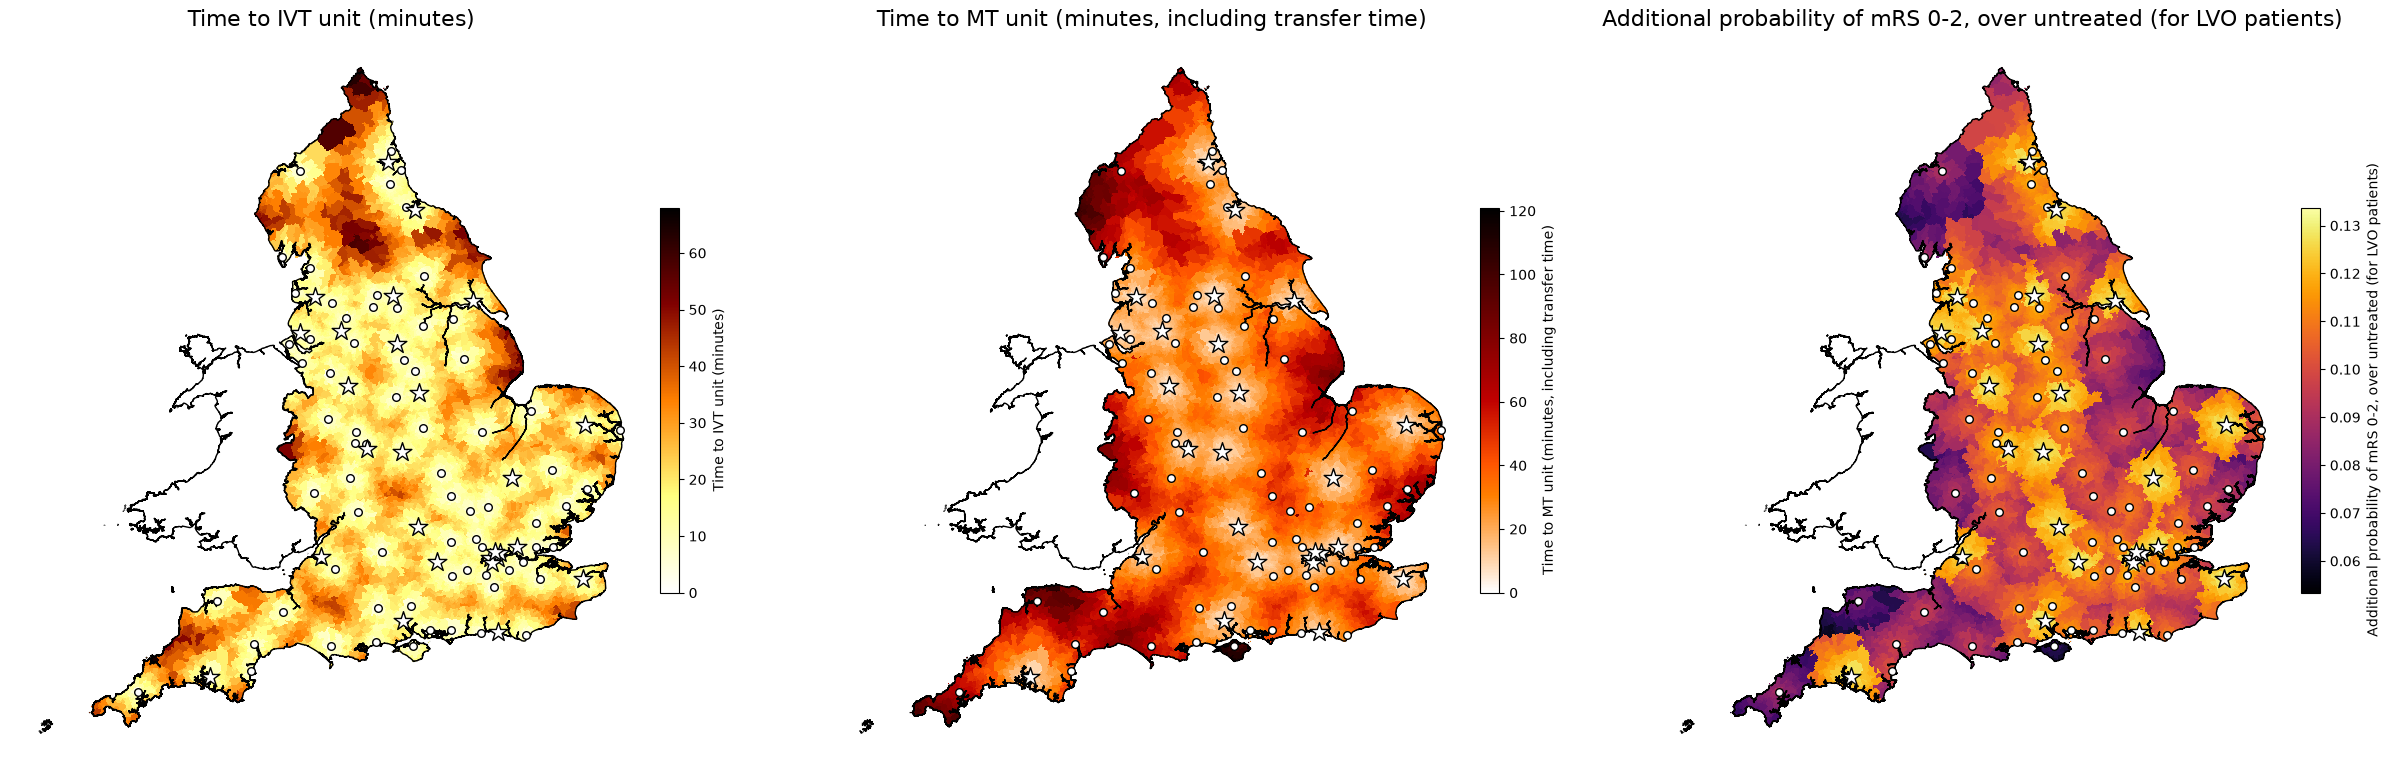

In [12]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

data['treated_improved_p_mrs_0-2'] = \
    data['lvo_drip_ship_ivt_mt_mrs_0-2'] - data['lvo_no_treatment_mrs_0-2']

columns = ['nearest_ivt_time_no_bias',
           'nearest_mt_time',
           'treated_improved_p_mrs_0-2']

color_schemes = ['afmhot_r',
                 'gist_heat_r',
                 'inferno']

labels = ['Time to IVT unit (minutes)',
          'Time to MT unit (minutes, including transfer time)',
          'Additional probability of mRS 0-2, over untreated (for LVO patients)']

fig = plt.figure(figsize=(30, 10))

for i in range(3):
    ax = fig.add_subplot(1, 3, i + 1)

    column = columns[i]
    values = pd.to_numeric(data[column], errors='coerce').astype(float)
    valid_values = values.where(np.isfinite(values))

    vmin, vmax = valid_values.min(), valid_values.max()
    if vmin == vmax:
        vmax = vmin + 1

    cmap = plt.get_cmap(color_schemes[i])
    norm = Normalize(vmin=vmin, vmax=vmax)

    # Use a temporary numeric column; GeoPandas handles the color mapping.
    data['_plot_value'] = values

    data.plot(
        column='_plot_value',
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        missing_kwds={'color': 'lightgrey'},
        antialiased=False,
        linewidth=0,
    )

    england.plot(ax=ax, edgecolor='k', facecolor='none', linewidth=1)

    ivt_mask = pd.to_numeric(hospitals_gdf['Use_IVT'], errors='coerce').eq(1)
    mt_mask = pd.to_numeric(hospitals_gdf['Use_MT'], errors='coerce').eq(1)

    hospitals_gdf.loc[ivt_mask].plot(
        ax=ax, edgecolor='k', facecolor='w', markersize=30, marker='o', zorder=99
    )
    hospitals_gdf.loc[mt_mask].plot(
        ax=ax, edgecolor='k', facecolor='w', markersize=200, marker='*', zorder=99
)

    fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        shrink=0.5,      # shrink the colorbar to 50% of its original size
        pad=0.01,        # gap between map and colorbar (default 0.05)
        fraction=0.05,   # width of colorbar relative to the axes
        label=labels[i],
    )

    ax.set_title(labels[i], fontsize=16)

    ax.apply_aspect()
    ax.set_axis_off()
    
plt.savefig(f'./output/map_three_in_one_{SCENARIO_NAME}_lvo.png', dpi=300, bbox_inches='tight')
plt.show()